# 04 · Statistical monitoring and temporal dependence

Real MetroPT-3 data. Run `python -m src.pipeline --csv data/raw/MetroPT3.csv` first to regenerate the analysis inputs. These notebooks also run directly on the aggregated outputs included in the delivery.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
ROOT = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
from src.config import ANALOG, DIGITAL
OUT = ROOT / 'data/processed'
x = pd.read_parquet(OUT / 'monitoring_5min.parquet')
events = pd.read_csv(ROOT / 'data/reference/failure_events.csv', parse_dates=['start','end'])
quality = json.loads((ROOT / 'reports/data_quality.json').read_text())
sns.set_theme(style='whitegrid', palette='colorblind')
pd.set_option('display.max_columns', 30)


## Why chronological validation matters
Sensor readings are autocorrelated. Random row splits would make future operating conditions visible during training. All reference scales use February only; March sets thresholds. Reported failure intervals do not tune any detector.

,sensor,adf_statistic,adf_p,n
0,TP2,-11.282898,1.441493e-20,7079
1,TP3,-16.192036,4.160988e-29,7079
2,H1,-13.038713,2.264643e-24,7079
3,DV_pressure,-12.805732,6.607225e-24,7079
4,Reservoirs,-16.192824,4.153559e-29,7079
5,Oil_temperature,-6.715035,3.599943e-09,7079
6,Motor_current,-11.182491,2.481017e-20,7079


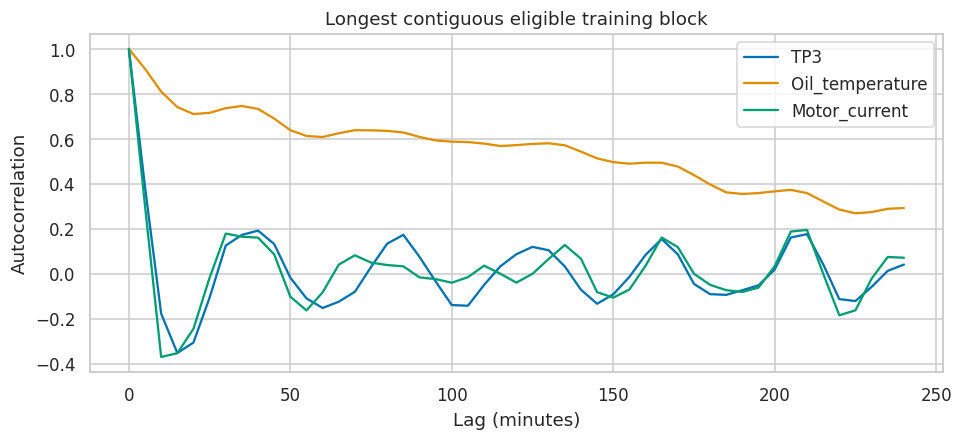

04_statistical_analysis.ipynb:cell2:6: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
04_statistical_analysis.ipynb:cell2:6: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
04_statistical_analysis.ipynb:cell2:6: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, 

In [2]:
from statsmodels.tsa.stattools import acf,adfuller
train=x.loc[x.split.eq('train') & x.quality_eligible,ANALOG]
rows=[]
for c in ANALOG:
    values=train[c].dropna().to_numpy()
    result=adfuller(values,maxlag=24,autolag=None)
    rows.append({'sensor':c,'adf_statistic':result[0],'adf_p':result[1],'n':len(values)})
display(pd.DataFrame(rows))
# Use one contiguous quality-eligible block for ACF, so removed gaps do not become adjacent.
flags=(x.split.eq('train') & x.quality_eligible)
groups=flags.ne(flags.shift()).cumsum()
longest=groups[flags].value_counts().idxmax()
block=x.loc[flags & groups.eq(longest)]
fig,ax=plt.subplots(figsize=(10,4))
for c in ['TP3','Oil_temperature','Motor_current']:
    ax.plot(np.arange(49)*5,acf(block[c].dropna(),nlags=48),label=c)
ax.set(xlabel='Lag (minutes)',ylabel='Autocorrelation',title='Longest contiguous eligible training block'); ax.legend(); plt.show()


ADF tests above use the eligible training sequence with gaps removed, so treat p-values as diagnostics, not proof of stationarity. The ACF plot deliberately uses a contiguous block. Large sample size can make small deviations statistically significant.

In [3]:
manifest=json.loads((ROOT/'reports/run_manifest.json').read_text())
display(pd.Series(manifest['thresholds'],name='Frozen validation threshold'))
methods=['zscore','rolling_z','threshold','cusum']
display(x.groupby('split')[[m+'_score' for m in methods]].quantile([.5,.95,.99]))
display(x.groupby('split')[[m+'_alert' for m in methods]].sum())


zscore                  39.326309
rolling_z              161.676378
cusum                   74.200894
isolation_forest         0.714896
mahalanobis         164862.576271
threshold                3.522292
Name: Frozen validation threshold, dtype: float64

zscore_score  rolling_z_score  threshold_score  cusum_score
split                                                                       
test       0.50      2.827179         1.440770         0.040274    22.530353
           0.95     14.320345         4.614609         1.552710    53.043607
           0.99    110.813562       282.552152        11.642573   110.359877
train      0.50      1.271047         1.503006        -0.000770     7.860902
           0.95      2.654803         3.741736         0.000015    40.643657
           0.99      7.003725       252.728013         0.061559    48.098776
validation 0.50      2.336709         1.377933         0.009646    21.317988
           0.95     34.729850         5.611849         2.999609    50.305068
           0.99     39.326309       161.676378         3.522292    74.200894

,zscore_alert,rolling_z_alert,threshold_alert,cusum_alert
split,,,,
test,1546,0,1547,1523
train,0,0,0,0
validation,61,0,60,66


## Detector behaviour
Global z-score captures distance from the training mean. Rolling z-score adapts to the preceding hour and can miss gradual drifts. Very small rolling variation can inflate its scores. Empirical thresholds are training distribution limits, not manufacturer limits. Two-sided CUSUM accumulates sustained change, resets on unavailable data and after a large excursion.

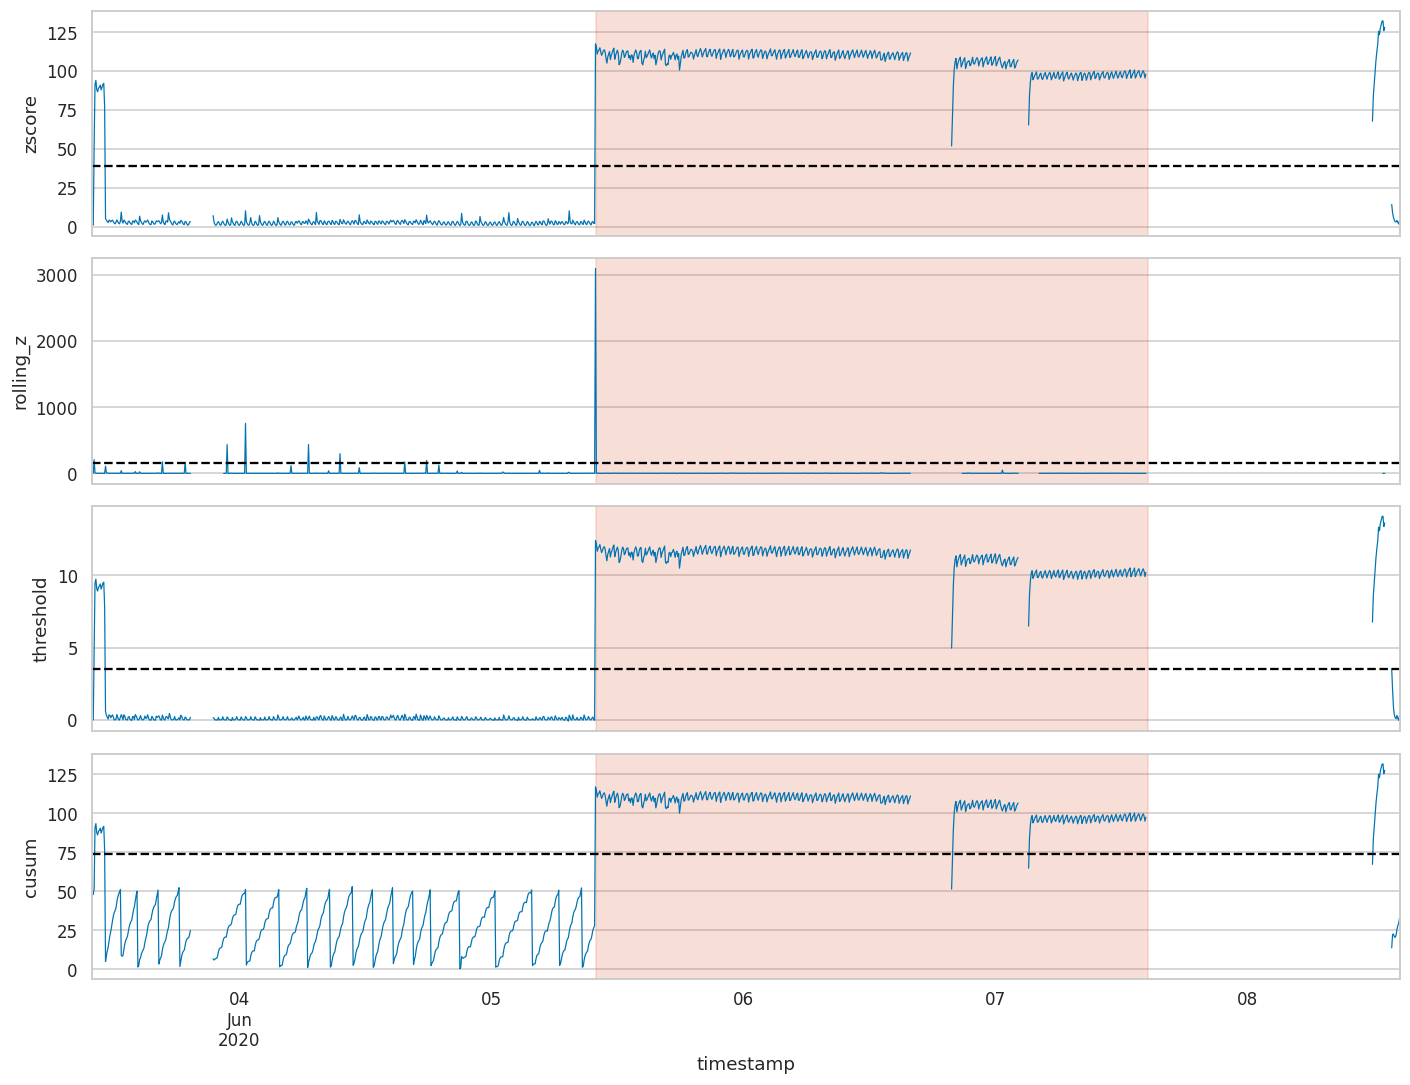

In [4]:
e=events.iloc[2]; segment=x.loc[e.start-pd.Timedelta('2d'):e.end+pd.Timedelta('1d')]
fig,axs=plt.subplots(4,1,figsize=(13,10),sharex=True)
for ax,m in zip(axs,methods):
    segment[m+'_score'].plot(ax=ax,lw=.8)
    ax.axhline(manifest['thresholds'][m],color='black',ls='--',label='Frozen threshold')
    ax.axvspan(e.start,e.end,color='#d95d39',alpha=.2)
    ax.set_ylabel(m)
plt.tight_layout(); plt.show()


In [5]:
# Compare daily means rather than pretending every ten-second record is independent.
from scipy.stats import ks_2samp
rows=[]
daily=x.loc[x.quality_eligible,ANALOG+['split']].groupby([pd.Grouper(freq='1D'),'split']).mean().reset_index()
for c in ANALOG:
    a=daily.loc[daily.split.eq('train'),c].dropna(); b=daily.loc[daily.split.eq('validation'),c].dropna()
    test=ks_2samp(a,b)
    rows.append({'sensor':c,'train_daily_mean':a.mean(),'validation_daily_mean':b.mean(),'KS_distance':test.statistic,'descriptive_p':test.pvalue})
display(pd.DataFrame(rows))


,sensor,train_daily_mean,validation_daily_mean,KS_distance,descriptive_p
0,TP2,0.536897,1.542873,0.838710,2.355653e-11
1,TP3,8.962043,9.038517,0.770737,2.568614e-09
2,H1,8.398903,7.440922,0.838710,2.355653e-11
3,DV_pressure,-0.015520,0.033093,0.322581,6.985964e-02
4,Reservoirs,8.964137,9.037833,0.770737,2.568614e-09
5,Oil_temperature,56.350685,62.212381,0.806452,2.195709e-10
6,Motor_current,1.242591,2.105887,0.770737,2.568614e-09


## Interpretation
Validation-period distribution shifts affect threshold sensitivity. The held-out results must report both alerts and missed reported events. A detector that produces no persistent test alerts has zero event recall; do not repair that result by selecting a threshold from the test labels. Follow-up threshold choices need a new validation period.